# Data Visualization with Matplotlib and Seaborn
**GDG on Campus, COMSATS University Attock Campus | AI/ML Team | Month 2, Week 1**

**Author:** Maryam Fatima (GitHub: maryam-ca)

This notebook contains all 14 tasks: 7 Matplotlib tasks and 7 Seaborn tasks. Every plot has a title, axis labels, a legend where relevant, and a short written insight underneath.

| Part | Tasks | Datasets |
|---|---|---|
| Part 1: Matplotlib | 7 | flights, tips, mpg |
| Part 2: Seaborn | 7 | titanic, penguins, tips |

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load all datasets once (they ship with Seaborn)
tips = sns.load_dataset("tips")
flights = sns.load_dataset("flights")
mpg = sns.load_dataset("mpg")
penguins = sns.load_dataset("penguins")
titanic = sns.load_dataset("titanic")

plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.labelsize"] = 11

for name, df in [("tips", tips), ("flights", flights), ("mpg", mpg), ("penguins", penguins), ("titanic", titanic)]:
    print(f"{name:<9} shape = {df.shape}")

tips      shape = (244, 7)
flights   shape = (144, 3)
mpg       shape = (398, 9)
penguins  shape = (344, 7)
titanic   shape = (891, 15)


---
# Part 1: Matplotlib Tasks

## Task 1: Line plot (flights)
Monthly passengers for one year (1960), with title, axis labels, markers and a grid.

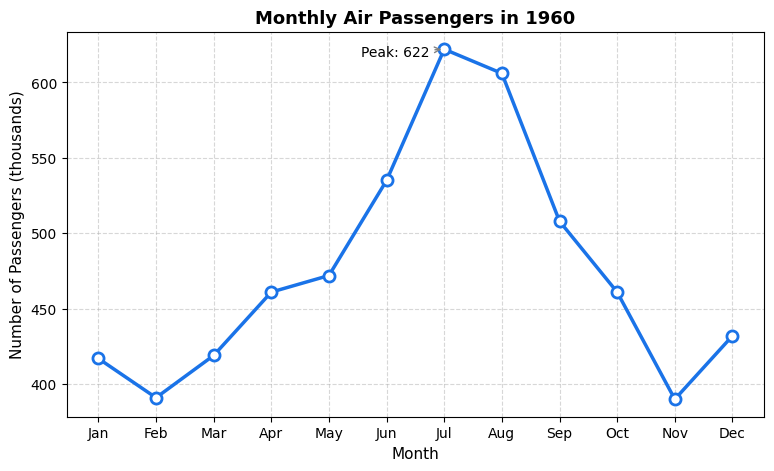

In [ ]:
f1960 = flights[flights["year"] == 1960]

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(f1960["month"].astype(str), f1960["passengers"],
        color="#1a73e8", linewidth=2.5, marker="o", markersize=8,
        markerfacecolor="white", markeredgewidth=2)
ax.set_title("Monthly Air Passengers in 1960")
ax.set_xlabel("Month")
ax.set_ylabel("Number of Passengers (thousands)")
ax.grid(True, linestyle="--", alpha=0.5)

# highlight the peak month
peak = f1960.loc[f1960["passengers"].idxmax()]
ax.annotate(f"Peak: {peak['passengers']}", xy=(str(peak["month"]), peak["passengers"]),
            xytext=(-60, -5), textcoords="offset points",
            arrowprops=dict(arrowstyle="->", color="gray"))
plt.show()

**Insight:** Air travel in 1960 is clearly seasonal. Passengers climb from spring to a peak in July (622), stay high in August (606), then fall to the lowest point in November (390). Summer holidays are the busiest travel period.

## Task 2: Bar chart (tips)
Average `total_bill` by day, with value labels on top of each bar and custom colors.

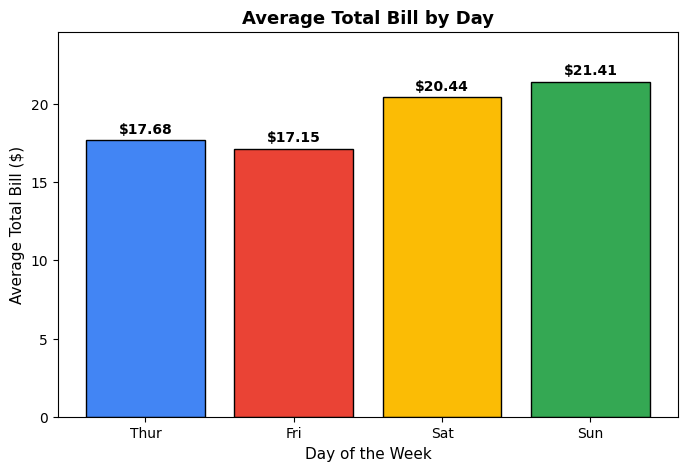

In [ ]:
avg_day = tips.groupby("day", observed=True)["total_bill"].mean()

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(avg_day.index.astype(str), avg_day.values,
              color=["#4285F4", "#EA4335", "#FBBC05", "#34A853"], edgecolor="black")
ax.bar_label(bars, fmt="$%.2f", padding=3, fontweight="bold")
ax.set_title("Average Total Bill by Day")
ax.set_xlabel("Day of the Week")
ax.set_ylabel("Average Total Bill ($)")
ax.set_ylim(0, avg_day.max() * 1.15)
plt.show()

**Insight:** Weekend bills are higher. Sunday ($21.41) and Saturday ($20.44) average about $3 more than Thursday ($17.68) and Friday ($17.15), probably because people dine in larger groups on weekends. The dataset only covers Thursday to Sunday.

## Task 3: Horizontal bar chart (mpg)
Average mpg by cylinders, sorted from highest to lowest.

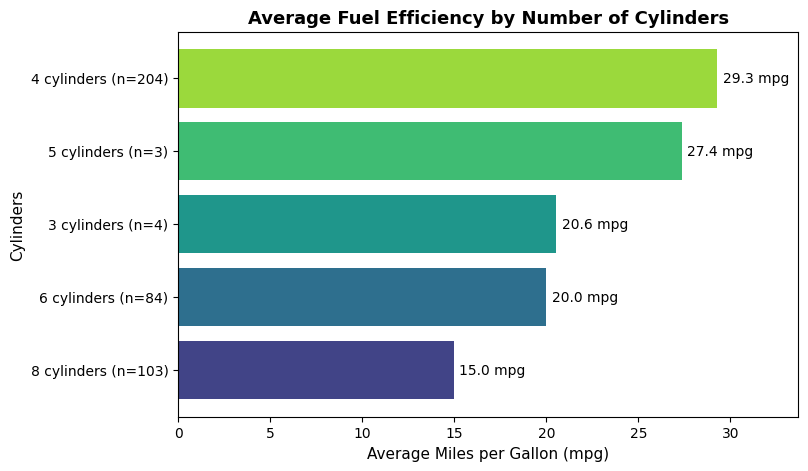

In [ ]:
avg_cyl = (mpg.groupby("cylinders")["mpg"].mean()
              .sort_values(ascending=False))          # highest -> lowest
counts = mpg["cylinders"].value_counts()

fig, ax = plt.subplots(figsize=(8, 5))
labels = [f"{c} cylinders (n={counts[c]})" for c in avg_cyl.index]
bars = ax.barh(labels, avg_cyl.values, color=plt.cm.viridis(np.linspace(0.85, 0.2, len(avg_cyl))))
ax.invert_yaxis()                                      # highest value on top
ax.bar_label(bars, fmt="%.1f mpg", padding=4)
ax.set_title("Average Fuel Efficiency by Number of Cylinders")
ax.set_xlabel("Average Miles per Gallon (mpg)")
ax.set_ylabel("Cylinders")
ax.set_xlim(0, avg_cyl.max() * 1.15)
plt.show()

**Insight:** 4-cylinder cars are the most efficient (29.3 mpg) and 8-cylinder cars the least (15.0 mpg), so larger engines burn much more fuel. The 3- and 5-cylinder bars rest on only 4 and 3 cars, so they are not reliable and explain why the order is not perfectly smooth.

## Task 4: Histogram (tips)
`total_bill` with 3 different bin sizes side by side, with vertical lines for the mean and median.

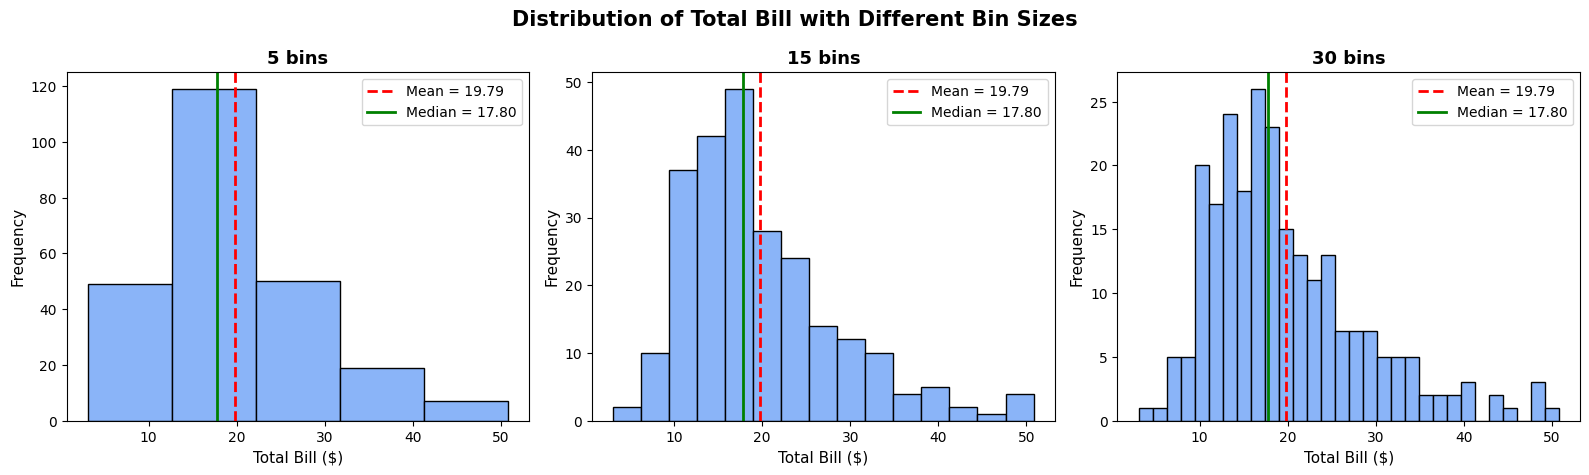

In [ ]:
bill = tips["total_bill"]
mean_v, median_v = bill.mean(), bill.median()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), sharey=False)
for ax, bins in zip(axes, [5, 15, 30]):
    ax.hist(bill, bins=bins, color="#8ab4f8", edgecolor="black")
    ax.axvline(mean_v, color="red", linestyle="--", linewidth=2, label=f"Mean = {mean_v:.2f}")
    ax.axvline(median_v, color="green", linestyle="-", linewidth=2, label=f"Median = {median_v:.2f}")
    ax.set_title(f"{bins} bins")
    ax.set_xlabel("Total Bill ($)")
    ax.set_ylabel("Frequency")
    ax.legend()
fig.suptitle("Distribution of Total Bill with Different Bin Sizes", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

**Insight:** The distribution is right-skewed: a few expensive bills pull the mean ($19.79) above the median ($17.80). Too few bins (5) hide the shape, while too many (30) look noisy. The 15-bin view shows most bills between about $10 and $25.

## Task 5: Scatter plot (mpg)
Weight vs mpg, with color for `origin`, point size for `horsepower`, and a legend.

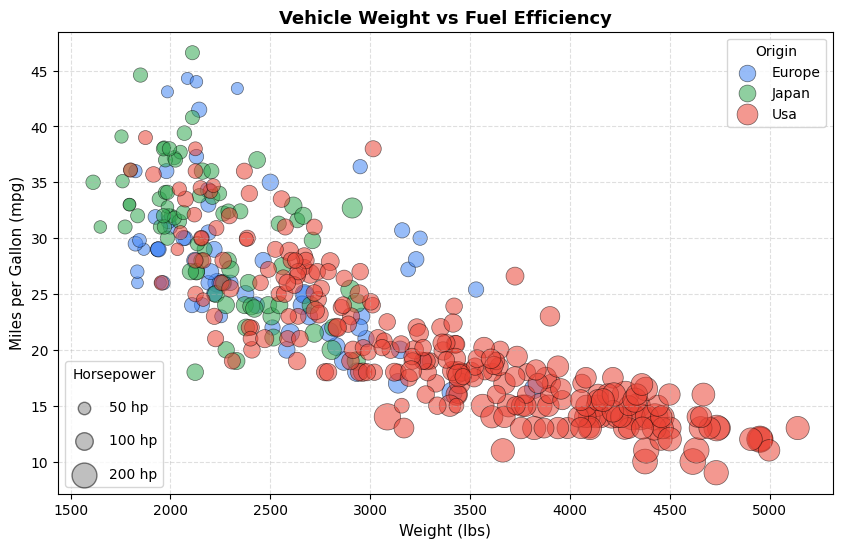

Correlation (weight, mpg): -0.83


In [ ]:
data = mpg.dropna(subset=["horsepower"])
colors = {"usa": "#EA4335", "japan": "#34A853", "europe": "#4285F4"}

fig, ax = plt.subplots(figsize=(10, 6))
for origin, g in data.groupby("origin"):
    ax.scatter(g["weight"], g["mpg"], s=g["horsepower"] * 1.6, c=colors[origin],
               alpha=0.55, edgecolor="black", linewidth=0.5, label=origin.title())

# color legend
leg1 = ax.legend(title="Origin", loc="upper right")
ax.add_artist(leg1)
# size legend
for hp in [50, 100, 200]:
    ax.scatter([], [], s=hp * 1.6, c="gray", alpha=0.5, edgecolor="black", label=f"{hp} hp")
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[3:], labels[3:], title="Horsepower", loc="lower left", labelspacing=1.4)

ax.set_title("Vehicle Weight vs Fuel Efficiency")
ax.set_xlabel("Weight (lbs)")
ax.set_ylabel("Miles per Gallon (mpg)")
ax.grid(True, linestyle="--", alpha=0.4)
plt.show()
print("Correlation (weight, mpg):", round(data["weight"].corr(data["mpg"]), 2))

**Insight:** Heavier cars get fewer miles per gallon (correlation about -0.83). American cars (red) are the heaviest, have the largest horsepower bubbles and average only 20.1 mpg, while Japanese (30.5 mpg) and European (27.9 mpg) cars are lighter and more efficient.

## Task 6: Pie / donut chart (tips)
Smoker vs non-smoker share with percentage labels.

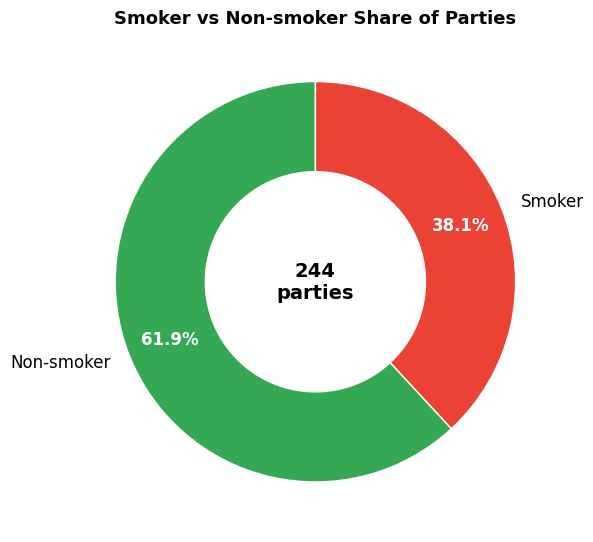

In [ ]:
smoker_counts = tips["smoker"].value_counts()

fig, ax = plt.subplots(figsize=(6.5, 6.5))
wedges, texts, autotexts = ax.pie(
    smoker_counts.values, labels=["Non-smoker" if s == "No" else "Smoker" for s in smoker_counts.index],
    autopct="%1.1f%%", startangle=90, colors=["#34A853", "#EA4335"],
    wedgeprops=dict(width=0.45, edgecolor="white"), pctdistance=0.78,
    textprops={"fontsize": 12})
for t in autotexts:
    t.set_color("white"); t.set_fontweight("bold")
ax.text(0, 0, f"{len(tips)}\nparties", ha="center", va="center", fontsize=14, fontweight="bold")
ax.set_title("Smoker vs Non-smoker Share of Parties")
plt.show()

**Insight:** Most parties are non-smokers (61.9%, 151 of 244) and 38.1% are smokers (93 of 244). Non-smoking parties are about 1.6 times as common.

## Task 7: Mini dashboard
A 2 x 2 subplot figure combining four earlier plots, using `tight_layout()` and saved as a PNG at `dpi=300`.

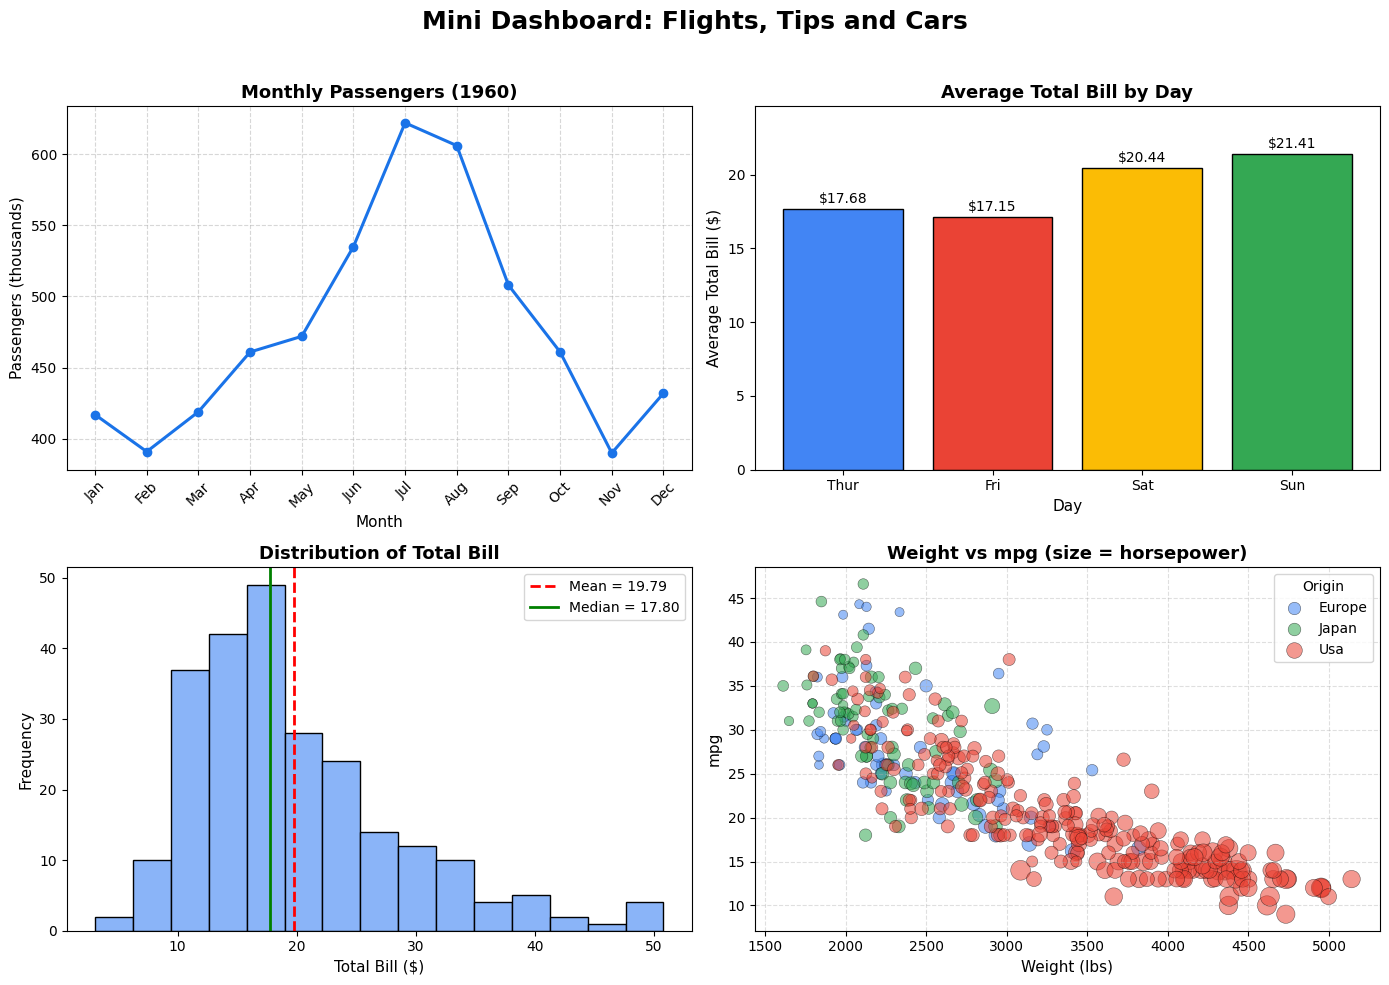

Saved: mini_dashboard.png (dpi=300)


In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# (1) Line: flights 1960
ax = axes[0, 0]
ax.plot(f1960["month"].astype(str), f1960["passengers"], color="#1a73e8", marker="o", linewidth=2.2)
ax.set_title("Monthly Passengers (1960)")
ax.set_xlabel("Month"); ax.set_ylabel("Passengers (thousands)")
ax.grid(True, linestyle="--", alpha=0.5)
ax.tick_params(axis="x", rotation=45)

# (2) Bar: tips by day
ax = axes[0, 1]
b = ax.bar(avg_day.index.astype(str), avg_day.values,
           color=["#4285F4", "#EA4335", "#FBBC05", "#34A853"], edgecolor="black")
ax.bar_label(b, fmt="$%.2f", padding=2)
ax.set_title("Average Total Bill by Day")
ax.set_xlabel("Day"); ax.set_ylabel("Average Total Bill ($)")
ax.set_ylim(0, avg_day.max() * 1.15)

# (3) Histogram: total_bill with mean/median
ax = axes[1, 0]
ax.hist(bill, bins=15, color="#8ab4f8", edgecolor="black")
ax.axvline(mean_v, color="red", linestyle="--", linewidth=2, label=f"Mean = {mean_v:.2f}")
ax.axvline(median_v, color="green", linewidth=2, label=f"Median = {median_v:.2f}")
ax.set_title("Distribution of Total Bill")
ax.set_xlabel("Total Bill ($)"); ax.set_ylabel("Frequency")
ax.legend()

# (4) Scatter: weight vs mpg by origin
ax = axes[1, 1]
for origin, g in data.groupby("origin"):
    ax.scatter(g["weight"], g["mpg"], s=g["horsepower"] * 0.9, c=colors[origin],
               alpha=0.55, edgecolor="black", linewidth=0.4, label=origin.title())
ax.set_title("Weight vs mpg (size = horsepower)")
ax.set_xlabel("Weight (lbs)"); ax.set_ylabel("mpg")
ax.legend(title="Origin")
ax.grid(True, linestyle="--", alpha=0.4)

fig.suptitle("Mini Dashboard: Flights, Tips and Cars", fontsize=18, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.96])
fig.savefig("mini_dashboard.png", dpi=300, bbox_inches="tight")
plt.show()
print("Saved: mini_dashboard.png (dpi=300)")

**Insight:** The dashboard shows four views side by side: flights are seasonal with a summer peak, weekend restaurant bills are higher, bills are right-skewed (mean above median), and heavier cars are less fuel efficient. A dashboard lets you compare several patterns at a glance, though each panel needs clear labels to stay readable.

---
# Part 2: Seaborn Tasks

## Task 1: Countplot (titanic)
Passengers by class with `hue` set to sex.

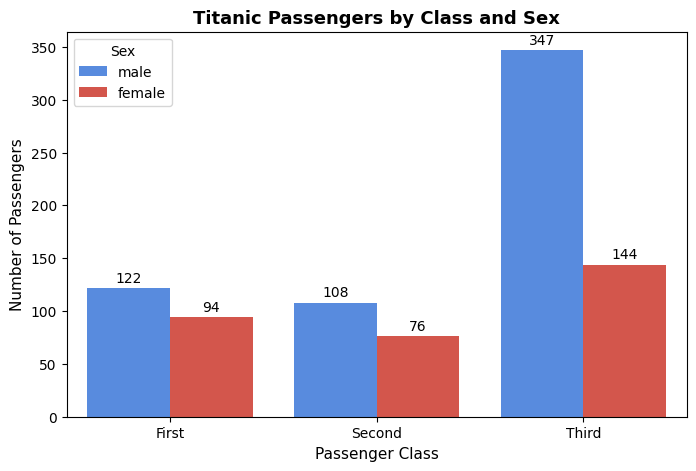

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.countplot(data=titanic, x="class", hue="sex", palette={"male": "#4285F4", "female": "#EA4335"}, ax=ax)
for c in ax.containers:
    ax.bar_label(c, padding=2)
ax.set_title("Titanic Passengers by Class and Sex")
ax.set_xlabel("Passenger Class")
ax.set_ylabel("Number of Passengers")
ax.legend(title="Sex")
plt.show()

**Insight:** Third class carried the most passengers (491), and it was heavily male (347 men vs 144 women). First and second class were smaller and more balanced, with first class having 122 men and 94 women.

## Task 2: Histogram with KDE (penguins)
`flipper_length_mm` for each species using `histplot(kde=True)`.

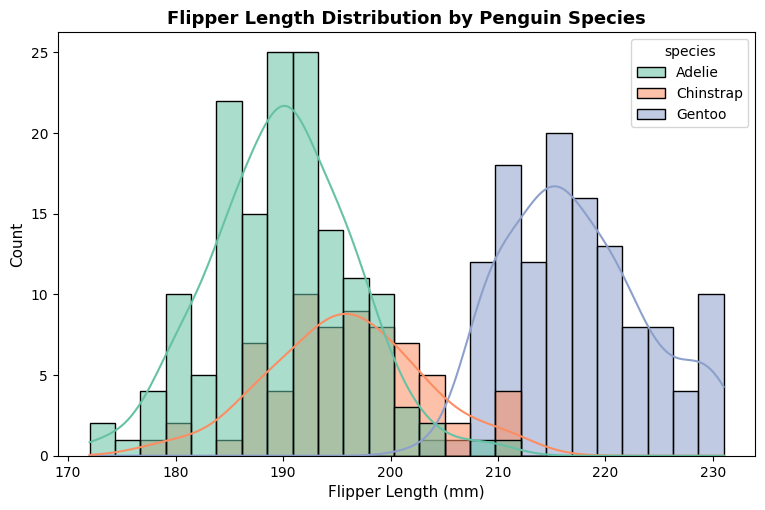

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5.5))
sns.histplot(data=penguins, x="flipper_length_mm", hue="species", kde=True,
             bins=25, palette="Set2", alpha=0.55, ax=ax)
ax.set_title("Flipper Length Distribution by Penguin Species")
ax.set_xlabel("Flipper Length (mm)")
ax.set_ylabel("Count")
plt.show()

**Insight:** Gentoo penguins have clearly longer flippers (mean about 217 mm) and barely overlap with the other species. Adelie (about 190 mm) and Chinstrap (about 196 mm) overlap heavily, so flipper length alone can separate Gentoo but not those two.

## Task 3: Box vs violin (penguins)
`body_mass_g` by species with both plot types side by side.

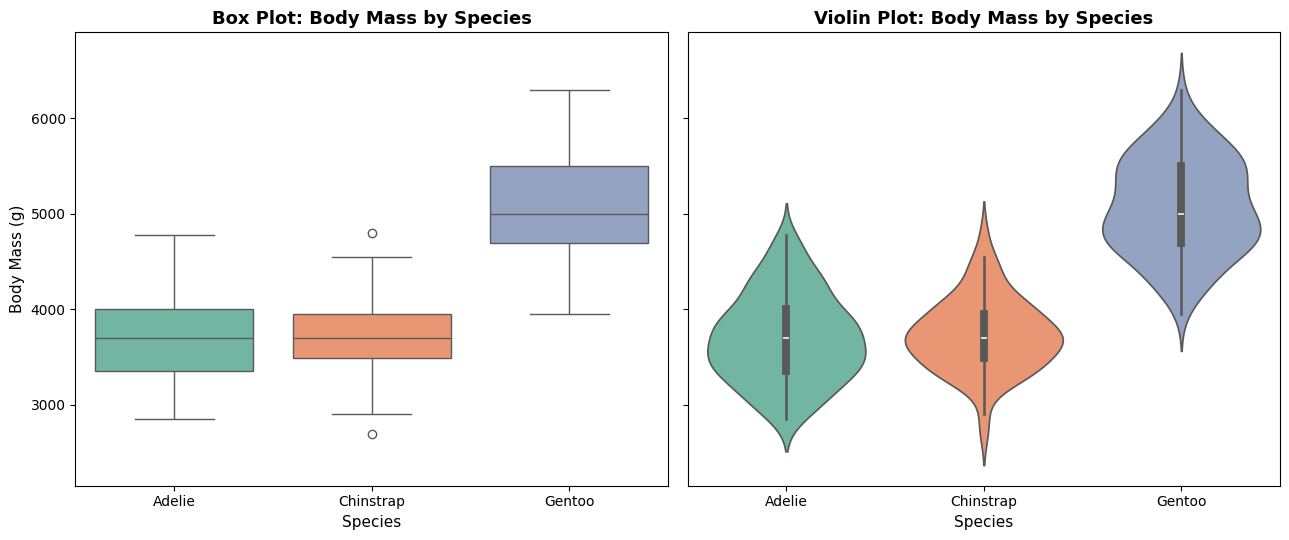

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharey=True)
sns.boxplot(data=penguins, x="species", y="body_mass_g", hue="species", palette="Set2", legend=False, ax=axes[0])
axes[0].set_title("Box Plot: Body Mass by Species")
axes[0].set_xlabel("Species"); axes[0].set_ylabel("Body Mass (g)")

sns.violinplot(data=penguins, x="species", y="body_mass_g", hue="species", palette="Set2", legend=False, ax=axes[1])
axes[1].set_title("Violin Plot: Body Mass by Species")
axes[1].set_xlabel("Species"); axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

**Insight (violin shows more):** The box plot summarises only the median, quartiles and outliers, while the violin plot also shows the full shape and density of the data. For example, Adelie and Chinstrap have almost the same median (about 3,700 g), but the violin shows that Chinstrap is more tightly concentrated around it. Gentoo is clearly the heaviest species in both plots (about 5,076 g).

## Task 4: Scatterplot (penguins)
`bill_length_mm` vs `bill_depth_mm` with `hue=species` and `style=sex`.

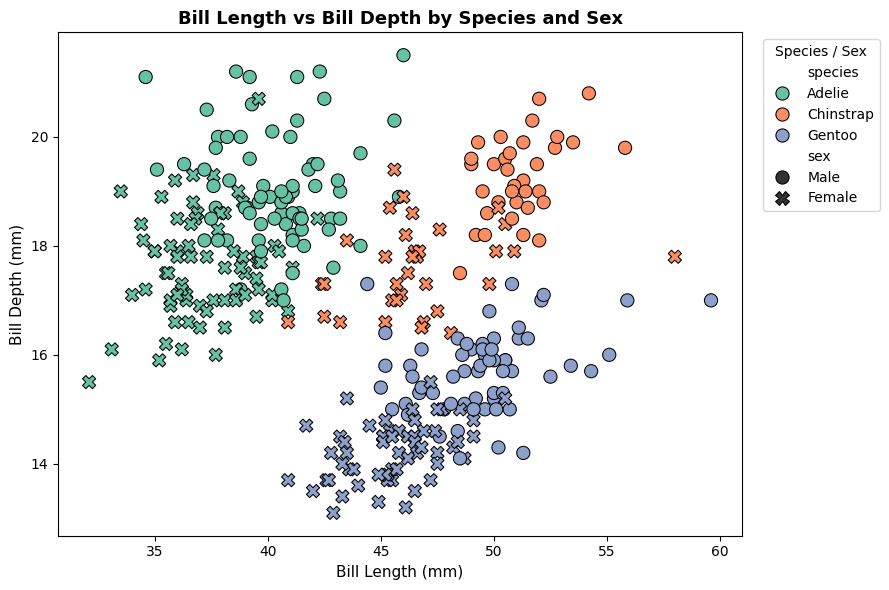

In [ ]:
fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(data=penguins, x="bill_length_mm", y="bill_depth_mm",
                hue="species", style="sex", palette="Set2", s=90, edgecolor="black", ax=ax)
ax.set_title("Bill Length vs Bill Depth by Species and Sex")
ax.set_xlabel("Bill Length (mm)")
ax.set_ylabel("Bill Depth (mm)")
ax.legend(title="Species / Sex", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

**Insight:** The three species form separate clusters: Adelie have short, deep bills; Chinstrap have long, deep bills; Gentoo have long, shallow bills. Within every species, males (average bill length 40-51 mm) sit higher and further right than females (37-47 mm), so males have larger bills.

## Task 5: Heatmap (penguins)
Correlation matrix of the numeric columns with `annot=True` and a diverging colormap.

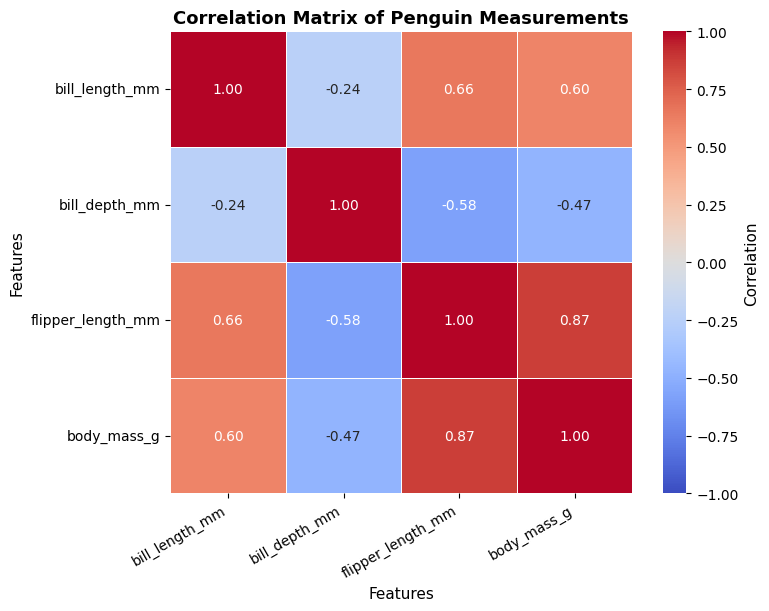

In [ ]:
corr = penguins.select_dtypes(include="number").corr()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1,
            linewidths=0.5, square=True, cbar_kws={"label": "Correlation"}, ax=ax)
ax.set_title("Correlation Matrix of Penguin Measurements")
ax.set_xlabel("Features")
ax.set_ylabel("Features")
plt.xticks(rotation=30, ha="right")
plt.show()

**Insight:** Flipper length and body mass have the strongest relationship (0.87), so bigger penguins have longer flippers. Bill depth is negatively correlated with flipper length (-0.58) and body mass (-0.47), which looks odd at first and is explained by the pairplot below (it comes from mixing species).

## Task 6: Pairplot (penguins)
Pairplot with `hue=species`, followed by 3 insights.

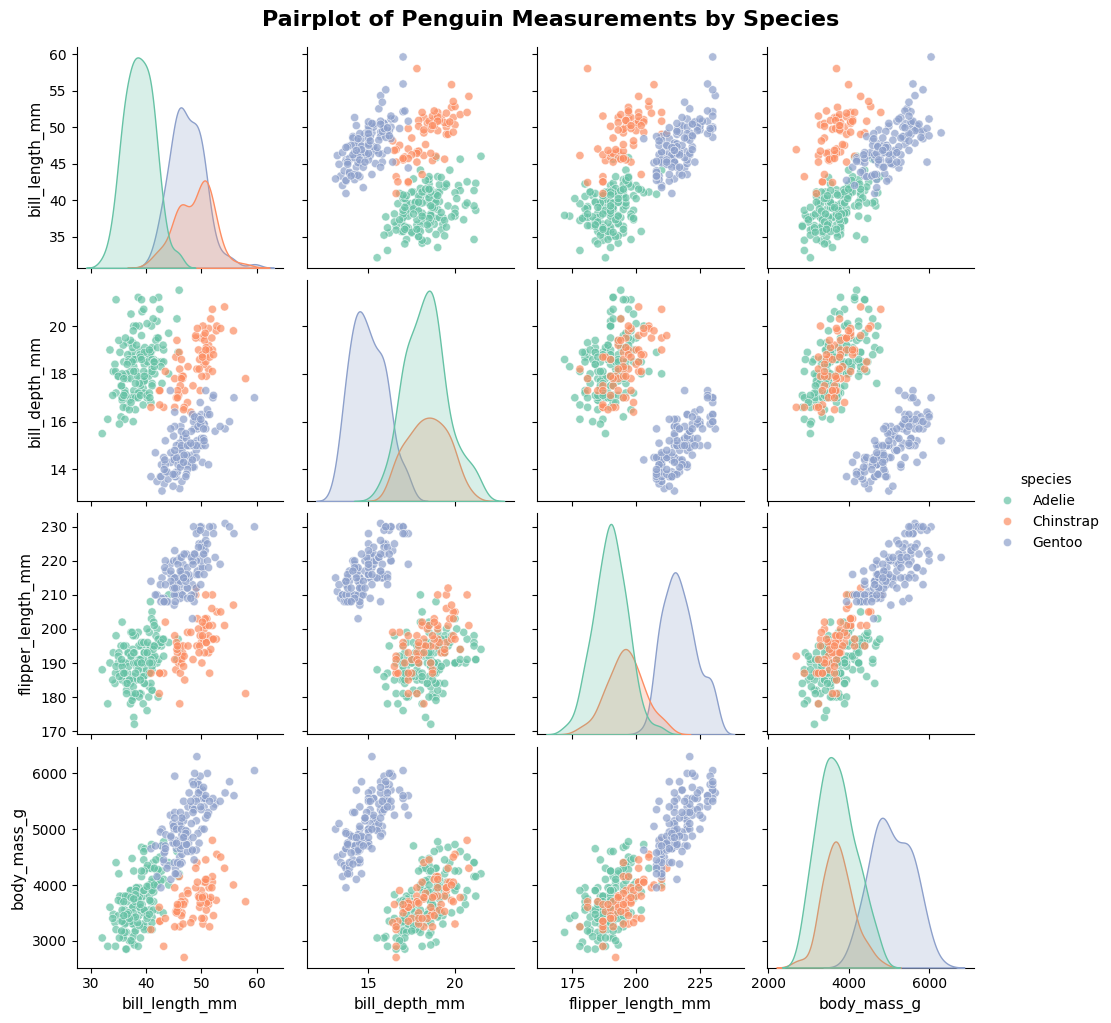

In [ ]:
g = sns.pairplot(penguins, hue="species", palette="Set2", diag_kind="kde",
                 corner=False, plot_kws={"alpha": 0.7, "s": 35})
g.fig.suptitle("Pairplot of Penguin Measurements by Species", y=1.02, fontsize=16, fontweight="bold")
plt.show()

**Three insights from the pairplot:**

1. **Gentoo stands apart.** In flipper length and body mass, Gentoo penguins form their own cluster away from Adelie and Chinstrap, which overlap on those two measurements.
2. **Chinstrap is separated by bill length.** Adelie and Chinstrap have similar size, but Chinstrap bills are clearly longer (about 49 mm vs 39 mm), so bill length is the best feature to tell those two apart.
3. **Simpson's paradox in bills.** Overall, bill length and depth look negatively related (-0.24), but inside each species the relationship is positive. The overall negative trend appears only because the species are mixed.

## Task 7: lmplot / FacetGrid (tips)
`total_bill` vs `tip` with a regression line, split by `time` and `smoker`, with a custom theme from `sns.set_theme()`.

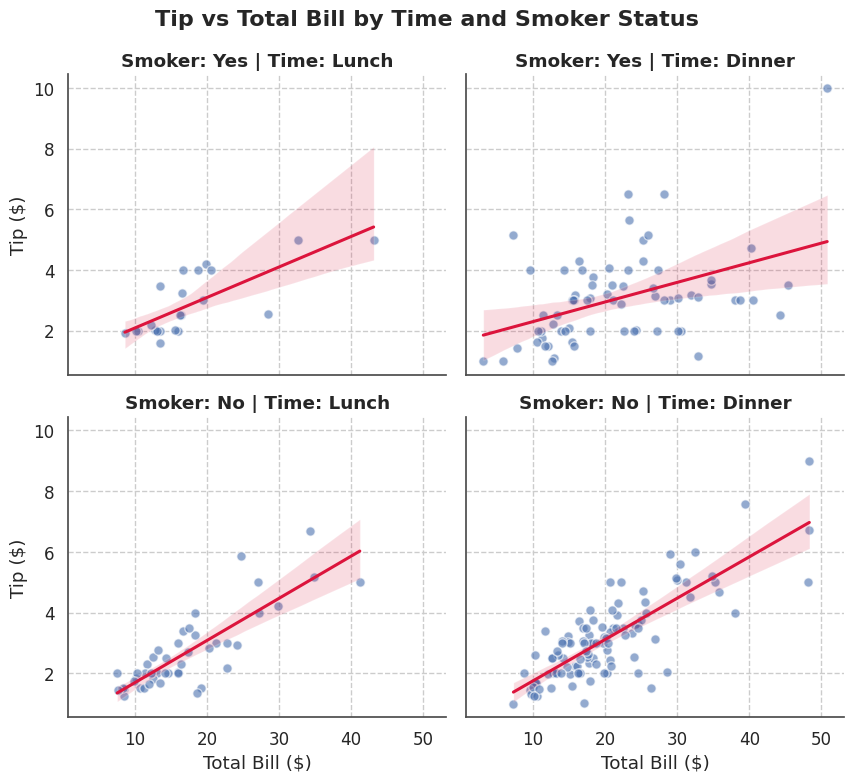

In [ ]:
sns.set_theme(style="whitegrid", palette="deep", font_scale=1.1,
              rc={"axes.edgecolor": "0.3", "grid.linestyle": "--"})

g = sns.lmplot(data=tips, x="total_bill", y="tip", col="time", row="smoker",
               height=3.8, aspect=1.15,
               scatter_kws={"alpha": 0.6, "s": 45, "edgecolor": "white"},
               line_kws={"color": "crimson", "linewidth": 2.2})
g.set_axis_labels("Total Bill ($)", "Tip ($)")
g.set_titles(row_template="Smoker: {row_name}", col_template="Time: {col_name}")
g.fig.suptitle("Tip vs Total Bill by Time and Smoker Status", y=1.03, fontsize=16, fontweight="bold")
plt.show()

**Insight:** In all four groups, bigger bills lead to bigger tips, with a strong linear relationship (correlation 0.75 to 0.84) in three of them. The exception is smokers at dinner, where the relationship is weaker (0.44) and tips vary more for the same bill. Non-smokers have the steepest lines, about 14 cents of tip per extra dollar of bill.

---
## Summary
All 14 tasks are complete: 7 Matplotlib (line, bar, horizontal bar, histogram, scatter, donut, dashboard) and 7 Seaborn (countplot, histplot with KDE, box vs violin, scatterplot, heatmap, pairplot, lmplot). The main findings are seasonal air travel, higher weekend bills, a clear weight vs mpg trade-off, and Gentoo penguins standing out in size.